# 10. Revisión sistemática ampliada y selección de los modelos

En este capítulo extendemos la revisión del capítulo 3. Documentamos las dos búsquedas, los criterios, el diagrama PRISMA y el acuerdo entre revisores. Presentamos la hoja de extracción y la calidad metodológica de los estudios, y seleccionamos y analizamos los siete modelos publicados del benchmark. Cerramos con la búsqueda transversal de mecanismos en otras modalidades y con la brecha de investigación. Los datos, las respuestas crudas de las bases y los scripts están en [`entregable2/revision_sistematica/`](https://github.com/Anyita-12/deep-learning-colaborativo/tree/main/entregable2/revision_sistematica).

In [1]:
import sys, json
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

import figuras as FG

FG.setup()
pd.set_option("display.max_colwidth", 80)
REV = E2 / "results" / "revision"
RS = E2 / "revision_sistematica" / "datos"
cr = pd.read_csv(REV / "cribado_e2.csv")
reg = pd.read_csv(RS / "registro_cadenas.csv", encoding="utf-8-sig")
hoja = pd.read_csv(RS / "hoja_extraccion.csv", encoding="utf-8-sig")
pc = json.load(open(RS / "prisma_conteos.json", encoding="utf-8"))
print(f"Cadenas registradas: {len(reg)} | estudios en la hoja de extracción: {len(hoja)} | elegibles para el benchmark: {int(cr.elegible_e2.sum())}")

Cadenas registradas: 30 | estudios en la hoja de extracción: 63 | elegibles para el benchmark: 36


## 10.1 Estrategia de búsqueda y bases de datos

La revisión combina dos búsquedas.

**Búsqueda original (7 de noviembre de 2026).** Es la del capítulo 3 y produce el PRISMA principal.

- **Cadenas exploratorias:** primero se probaron cuatro cadenas amplias en Scopus, entre las 16:25 y las 16:30. Dieron 1407, 982, 559 y 477 resultados y se descartaron por ruido: residuos de construcción, rutas de recolección y espectroscopía.
- **Cadena definitiva:** "TrashNet", que restringe la revisión a estudios comparables con nuestro conjunto de datos.

| Base | Hora | Cadena exacta | Filtros | Resultados finales |
|---|---|---|---|---|
| Scopus | 16:29 | `TITLE-ABS-KEY ( "TrashNet" ) AND PUBYEAR > 2017 AND PUBYEAR < 2027 AND ( DOCTYPE ( ar ) OR DOCTYPE ( cp ) ) AND LANGUAGE ( english )` | En la cadena | 161 |
| IEEE Xplore | 16:43 | `(("Document Title":"TrashNet") OR ("Abstract":"TrashNet") OR ("Author Keywords":"TrashNet"))` | 2018–2026 | 76 |
| Web of Science | 16:54 | `TS=("TrashNet") AND PY=(2018-2026) AND DT=("Article" OR "Proceedings Paper") AND LA=("English")` | En la consulta | 60 |
| arXiv (complementaria) | 17:15 | `all=TrashNet` | 2018–2026 | 4 |

**Búsqueda ampliada (16 de noviembre de 2026).** Mide qué deja fuera la restricción a "TrashNet". Se ejecutó en IEEE Xplore (campo *All Metadata*) y en arXiv y OpenAlex por API, que permiten descargar y guardar los registros completos. Usa tres cadenas sobre el problema:

- **P1:** dominio, tarea y método con sinónimos;
- **P2:** "TrashNet";
- **P3:** transferencia desde modelos preentrenados.

La consulta exacta enviada a cada base, la fecha y hora (UTC) y el número de resultados están en [`entregable2/revision_sistematica/datos/registro_cadenas.csv`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/revision_sistematica/datos/registro_cadenas.csv). IEEE Xplore, una de las bases principales del área, aporta los conteos de referencia. arXiv y OpenAlex complementan la búsqueda porque sus API permiten guardar, deduplicar y cribar de forma reproducible todos los registros recuperados.

**Periodo:** 2018–2026. TrashNet se publicó en 2016–2017 y la literatura de Deep Learning sobre el problema empieza en 2018. Los trabajos fundacionales anteriores se admiten solo como fuentes primarias de mecanismos (sección 10.8).

In [2]:
r = reg.copy()
r["base_corta"] = r.base.str.split(" ").str[0]
tab = r[r.tipo == "principal"].pivot_table(index="id", columns="base_corta", values="n_resultados", aggfunc="first")
display(tab)

base_corta,IEEE,OpenAlex,arXiv
id,,,
P1,1839,3326,88
P2,77,242,4
P3,208,150,7


## 10.2 Criterios de inclusión y exclusión

**Inclusión (todos deben cumplirse):**

| Código | Criterio |
|---|---|
| I1 | Estudio primario: artículo de revista, congreso o preprint |
| I2 | Residuos sólidos domésticos o municipales reciclables |
| I3 | Datos de imagen (RGB) |
| I4 | Tarea de clasificación o reconocimiento del tipo de residuo |
| I5 | Método de Deep Learning |
| I6 | Publicado entre 2018 y 2026 |

**Exclusión por título y resumen** (se registra la primera regla que falla):

| Código | Motivo |
|---|---|
| X0 | Documento no elegible: tesis, conjunto de datos, software, editorial, libro, resumen, fe de erratas |
| X1 | Revisión, encuesta o estudio bibliométrico |
| X2 | Fuera del dominio: "waste" en otro sentido, residuos de alimentos, electrónicos, de construcción, médicos o aguas residuales |
| X3 | No usa imágenes |
| X4 | Tarea distinta de la clasificación: detección, segmentación, conteo o predicción |
| X5 | No usa Deep Learning |

**A texto completo** se exigen métricas reportadas, detalle suficiente para reproducir (arquitectura, partición y entrenamiento) o código, y una revista o congreso de calidad verificable. La calidad de la revista se mide con el *2-year mean citedness* de OpenAlex en todos los estudios y con el cuartil SJR en los siete del benchmark.

## 10.3 Diagrama PRISMA 2020 y acuerdo entre revisores

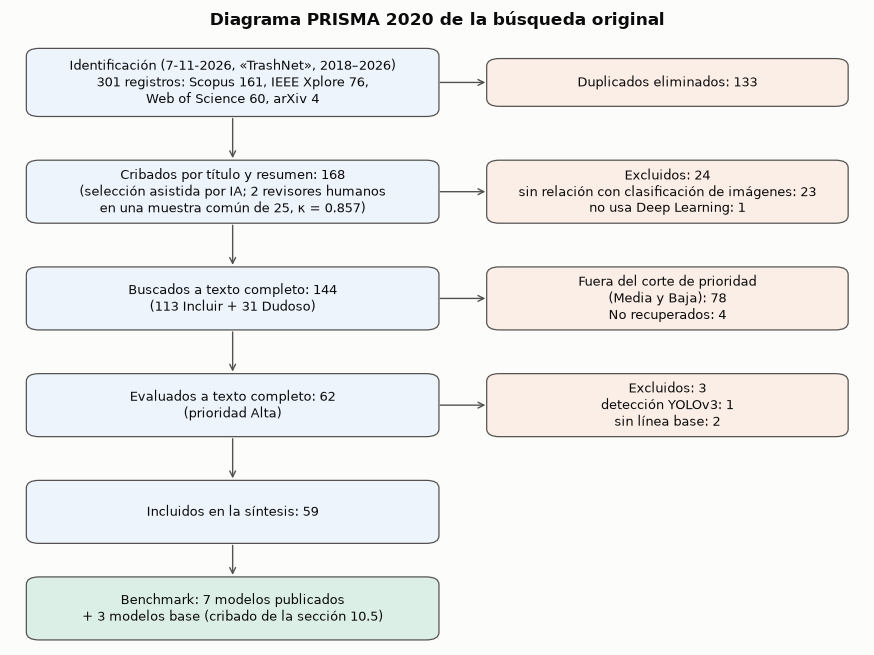

In [3]:
fig, ax = plt.subplots(figsize=(10, 7.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 12); ax.axis("off")
def caja(x, y, w, h, txt, fc="#eef4fc"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=fc, ec=FG.INK2, lw=0.8))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=8.4, color=FG.INK)
def flecha(x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color=FG.INK2, lw=0.9))
caja(0.2, 10.4, 4.8, 1.3, "Identificación (7-11-2026, «TrashNet», 2018–2026)\n301 registros: Scopus 161, IEEE Xplore 76,\nWeb of Science 60, arXiv 4")
caja(5.6, 10.6, 4.2, 0.9, "Duplicados eliminados: 133", fc="#fbeee7")
caja(0.2, 8.3, 4.8, 1.2, "Cribados por título y resumen: 168\n(selección asistida por IA; 2 revisores humanos\nen una muestra común de 25, κ = 0.857)")
caja(5.6, 8.3, 4.2, 1.2, "Excluidos: 24\nsin relación con clasificación de imágenes: 23\nno usa Deep Learning: 1", fc="#fbeee7")
caja(0.2, 6.2, 4.8, 1.2, "Buscados a texto completo: 144\n(113 Incluir + 31 Dudoso)")
caja(5.6, 6.2, 4.2, 1.2, "Fuera del corte de prioridad\n(Media y Baja): 78\nNo recuperados: 4", fc="#fbeee7")
caja(0.2, 4.1, 4.8, 1.2, "Evaluados a texto completo: 62\n(prioridad Alta)")
caja(5.6, 4.1, 4.2, 1.2, "Excluidos: 3\ndetección YOLOv3: 1\nsin línea base: 2", fc="#fbeee7")
caja(0.2, 2.0, 4.8, 1.2, "Incluidos en la síntesis: 59")
caja(0.2, 0.1, 4.8, 1.2, f"Benchmark: 7 modelos publicados\n+ 3 modelos base (cribado de la sección 10.5)", fc="#dcefe6")
for y0, y1 in [(10.4, 9.5), (8.3, 7.4), (6.2, 5.3), (4.1, 3.2), (2.0, 1.3)]:
    flecha(2.6, y0, 2.6, y1)
for y in (11.05, 8.9, 6.8, 4.7):
    flecha(5.0, y, 5.6, y)
ax.set_title("Diagrama PRISMA 2020 de la búsqueda original")
plt.show()

**Priorización de la lectura a texto completo.** La lectura a texto completo se concentró en los 62 registros de prioridad Alta: artículos de revista marcados como Incluir o registros con al menos 10 citas. Este criterio dirige el análisis detallado a los estudios de mayor impacto y con revisión por pares completa, que son los que la comunidad usa como referencia. Los 78 registros de prioridad Media o Baja (en su mayoría ponencias con menos de 10 citas) quedan identificados y clasificados en la hoja `Registros` del Excel de selección. La búsqueda ampliada confirma que el núcleo de la literatura comparable está cubierto (sección 10.3).

**Selección y acuerdo entre revisores.** El cribado por título y resumen de los 168 registros lo hizo de forma preliminar un asistente de IA (Claude), con la hoja de criterios del Excel. Dos revisores humanos (H1 y H2) decidieron de forma independiente una muestra común de 25 registros:

| Comparación (n = 25) | Acuerdo observado | κ de Cohen (Incluir, Dudoso, Excluir) | κ de Cohen (pasa o se excluye) |
|---|---|---|---|
| H1 frente a H2 | 0.92 | **0.857** | **1.000** |
| H1 frente a IA | 0.92 | 0.860 | 0.896 |
| H2 frente a IA | 0.96 | 0.925 | 0.896 |

El acuerdo entre los revisores humanos es casi perfecto (Landis y Koch, 1977), y coinciden en los 25 registros en la decisión de pasar o no a texto completo. Las dos discrepancias (R100 y R132) se resolvieron por mayoría de los tres revisores; sin mayoría, el registro pasaba a texto completo como Dudoso. La lectura a texto completo fue asistida por IA, y los siete estudios del benchmark se verificaron a mano.

In [4]:
fl = pd.DataFrame({"etapa": ["Identificados en OpenAlex (P1 + P2 + P3)", "Identificados en arXiv", "Solo conteo en IEEE Xplore (P1 + P2 + P3)",
                             "Duplicados eliminados", "Cribados por título y resumen", "Excluidos por reglas (X0–X5)", "Pasan el cribado",
                             "Registros del corpus original recuperados"],
                   "n": [pc["identificados_por_base"]["OpenAlex"], pc["identificados_por_base"]["arXiv"], pc["solo_conteo_IEEE_Xplore"]["total"],
                         pc["duplicados_eliminados"], pc["cribados"], pc["cribados"] - pc["decisiones"]["INCLUIDO"],
                         pc["decisiones"]["INCLUIDO"], f"{pc['corpus_recuperado']} de {pc['corpus_total']}"]})
display(fl)
display(pd.Series({k: v for k, v in pc["decisiones"].items() if k != "INCLUIDO"}, name="excluidos").to_frame())

,etapa,n
0,Identificados en OpenAlex (P1 + P2 + P3),3718
1,Identificados en arXiv,99
2,Solo conteo en IEEE Xplore (P1 + P2 + P3),2124
3,Duplicados eliminados,383
4,Cribados por título y resumen,3434
5,Excluidos por reglas (X0–X5),1876
6,Pasan el cribado,1558
7,Registros del corpus original recuperados,60 de 63


,excluidos
"X0 tipo de documento no elegible (libro, capítulo, tesis, dataset u otro)",198
"X1 revisión o encuesta, no estudio primario",146
X2 fuera del dominio de residuos,1278
"X3 no usa imágenes (sensores, espectros, texto o series)",2
"X4 tarea distinta de clasificación (detección, segmentación, conteo, predicción)",241
X5 no usa Deep Learning,11


**Cobertura de la búsqueda original.** La búsqueda ampliada recupera 60 de los 63 registros del corpus (95 %). El único registro recuperado que sus reglas excluyen (R007, detección) es el mismo que el equipo excluyó a texto completo, lo que muestra que los criterios de las dos búsquedas son coherentes. La búsqueda ampliada identifica además unos 1500 trabajos de clasificación de residuos con otros conjuntos de datos. No entran en la síntesis, porque sus resultados no son comparables con un benchmark sobre TrashNet, y quedan registrados en `cribado_principal.csv` como base para extender la revisión a otros conjuntos de datos.

El cribado automático de la búsqueda ampliada se contrastó con un segundo revisor asistido por IA, que decidió sin ver la decisión de las reglas:

- **Muestra de calibración:** 60 registros, con los que se corrigieron las reglas.
- **Muestra de validación:** 60 registros nuevos, con acuerdo de 0.833, κ = 0.669, sensibilidad de 0.93 y precisión de 0.77. Las reglas son conservadoras.

## 10.4 Hoja de extracción y calidad metodológica

La hoja de extracción ([`entregable2/revision_sistematica/datos/hoja_extraccion.csv`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/revision_sistematica/datos/hoja_extraccion.csv)) tiene una fila por cada uno de los 63 registros del corpus y campos fijos:

- **Identificación:** autores, año, título, DOI, revista y tipo;
- **Impacto:** citas en OpenAlex y *2-year mean citedness* de la revista;
- **Arquitectura y datos:** familias, conjuntos de datos, partición, *k-fold* y conjunto de validación;
- **Resultados:** métricas y accuracy;
- **Rigor:** repeticiones o semillas, pruebas estadísticas, código público, baselines ajustados por igual y control de duplicados;
- **Calidad:** riesgo de fuga, repeticiones y equidad de los baselines.

La extracción se hizo con patrones explícitos sobre el texto completo ([`entregable2/revision_sistematica/scripts/extraccion.py`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/revision_sistematica/scripts/extraccion.py)), y los siete estudios del benchmark se verificaron a mano. Las filas automáticas son orientativas.

In [5]:
inc = hoja[hoja.decision_TC_equipo == "Incluir"]
def cuenta(col, cond):
    return int(cond(inc[col].astype(str)).sum())
sint = pd.DataFrame({
    "indicador (59 incluidos)": ["Declara un conjunto de validación separado", "Usa validación cruzada k-fold", "Reporta más de una corrida o semilla",
                                 "Usa alguna prueba estadística", "Código público oficial", "Declara baselines ajustados por igual",
                                 "Riesgo de fuga alto", "Riesgo de fuga medio", "Riesgo de fuga bajo"],
    "estudios": [cuenta("conjunto_validacion", lambda s: s == "Sí"), cuenta("k_fold", lambda s: ~s.str.startswith("No")),
                 cuenta("repeticiones", lambda s: s.str.startswith("Varias")), cuenta("pruebas_estadisticas", lambda s: s != "No"),
                 cuenta("codigo_publico", lambda s: s == "Sí, oficial"), cuenta("equidad_baselines", lambda s: s == "Declarada"),
                 cuenta("riesgo_fuga", lambda s: s.str.startswith("Alto")), cuenta("riesgo_fuga", lambda s: s.str.startswith("Medio")),
                 cuenta("riesgo_fuga", lambda s: s.str.startswith("Bajo"))]})
sint["%"] = (100 * sint.estudios / len(inc)).round(0).astype(int)
display(sint)

,indicador (59 incluidos),estudios,%
0,Declara un conjunto de validación separado,24,41
1,Usa validación cruzada k-fold,19,32
2,Reporta más de una corrida o semilla,9,15
3,Usa alguna prueba estadística,9,15
4,Código público oficial,2,3
5,Declara baselines ajustados por igual,12,20
6,Riesgo de fuga alto,25,42
7,Riesgo de fuga medio,34,58
8,Riesgo de fuga bajo,0,0


**Calidad metodológica.** Clasificamos el riesgo de fuga en tres niveles:

- **Alto:** no hay validación separada, o el conjunto de prueba selecciona el modelo.
- **Medio:** hay validación o *k-fold*, pero sin control de duplicados.
- **Bajo:** validación separada y control de duplicados.

Ninguno de los 59 estudios alcanza riesgo bajo, porque ninguno controla los casi-duplicados de TrashNet que el capítulo 2 identificó. 50 reportan una sola corrida y 47 no declaran que sus baselines se ajustaran con el mismo protocolo. En la hoja de calidad del capítulo 3, 13 de los 59 estudios usaban pruebas estadísticas; la extracción de esta etapa, con patrones más estrictos, encuentra 9. Con cualquiera de los dos conteos, la conclusión es la misma: la literatura sobre TrashNet casi nunca reporta varianza entre semillas ni pruebas de hipótesis.

**Los siete estudios del benchmark (verificados a mano).**

| Modelo | Estudio | Partición | Validación separada | Repeticiones | Pruebas estadísticas | Código | Accuracy publicada | Citas (OpenAlex) | Cuartil SJR (año de publicación) | Riesgo de fuga |
|---|---|---|---|---|---|---|---|---|---|---|
| Celik-HC (guía) | Celik (2025), *The Visual Computer* | 80/20 aleatoria | No: la época se elige con la prueba | Una | No | Sí, oficial | 99.40 % | 15 | Q2 | Alto |
| MbXception | Shi et al. (2020), *IEEE Access* | No reportada | No declarada | Una | No | Sí, oficial | 94.34 % | 64 | Q1 | Alto |
| ViT-B16 | Huang K. et al. (2021), *Sustainability* | 70/13/17 | Sí | Una | No | No | 96.98 % | 68 | Q1/Q2 según la categoría | Medio |
| GFN | Wang Z. et al. (2025), *Electronics* | 80/10/10 | Sí | Una | No | No | 94.21 % | 20 | Q2 | Medio |
| FocusRCNet | Zheng D. et al. (2023), *VCIBA* | 70/30 | La validación hace de prueba | Una | No | No | ~92 % | 21 | Q2 | Alto |
| ResMsCapsule | Huang L. et al. (2023), *ESPR* | 80/20, cuatro clases | No declarada | Media y DE por variante | No | No | 91.41 % | 10 | Q1/Q2 según la categoría | Alto |
| RWCNet | Hossen et al. (2024), *IEEE Access* | 70/20/10 con 5 pliegues | Sí | 5 pliegues | No | No | 95.01 % | 127 | Q1 | Medio |

Cuatro de los siete se publicaron en revistas Q1. El paper guía (Q2) es el de mayor accuracy publicada y el que más se aleja en la réplica (capítulo 12). Ninguno compara modelos con pruebas de hipótesis.

**Reproducibilidad de la literatura.** Solo 2 de los 59 estudios publican su código oficial (Celik, 2025; Shi et al., 2020). Otros tres ofrecen código parcial, de terceros o a petición, y ninguno publica la partición usada. Esta escasez explica la elección del paper guía: era el único con código completo, condición necesaria para la réplica.

## 10.5 Selección de los modelos del benchmark

Sobre los 62 estudios evaluados a texto completo aplicamos criterios propios del benchmark. Garantizan una comparación justa con un presupuesto de cómputo común y se aplican en orden; el primero que se cumple es el motivo registrado.

| Código | Criterio de exclusión para el benchmark | Fuente de la evidencia |
|---|---|---|
| E0 | Excluido a texto completo en el capítulo 3 | Hoja `Registros` |
| E1 | TrashNet no es el conjunto principal de evaluación (menos de 3 menciones) | Texto completo |
| E2 | No evalúa las seis clases de TrashNet | Texto completo |
| E3 | La contribución depende de metaheurísticas, aprendizaje por refuerzo, GAN o aprendizaje federado, que entrenan el modelo decenas de veces y rompen la igualdad de presupuesto | Título y resumen |
| E4 | Detección de objetos y no clasificación | Título y resumen |
| E5 | Ensamble de varias redes completas (presupuesto desigual) | Título y resumen |

Los indicadores son recuentos de términos, reproducibles con `entregable2/analisis/revision_e2.py`. La decisión de cada estudio está en [`entregable2/results/revision/cribado_e2.csv`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/results/revision/cribado_e2.csv).

In [6]:
mot = cr.motivo_exclusion_e2.fillna("").replace("", "Elegible").str.replace(r"^(E\d): .*", r"\1", regex=True)
display(mot.value_counts().rename("estudios").to_frame())

,estudios
motivo_exclusion_e2,
Elegible,36
E3,12
E5,5
E2,4
E0,3
E1,1
E4,1


ResMsCapsule es la única excepción al criterio E2: su artículo reporta resultados con cuatro clases. Lo incluimos porque es el único representante de la familia de redes de cápsulas, necesaria para la diversidad del benchmark, y lo entrenamos con las seis clases de TrashNet bajo el protocolo común. Su valor publicado no es comparable con el nuestro, y la adaptación se registra como desviación en el capítulo 11.

### Puntaje de priorización

La selección siguió cuatro requisitos, definidos antes de ver los resultados del benchmark:

1. un paper guía con código público completo, que permita la réplica del capítulo 12;
2. arquitectura definida en el artículo;
3. entrenamiento factible con el presupuesto común;
4. diversidad de al menos cuatro familias.

Para hacer la priorización reproducible, calculamos, sobre los estudios elegibles, un puntaje con cuatro componentes de igual peso en $[0, 1]$:

- **citas normalizadas por antigüedad:** percentil de citas por año en OpenAlex, consultadas el 16 de noviembre de 2026;
- **recencia:** $(\text{año} - 2018)/8$;
- **desempeño reportado en TrashNet:** $(\text{accuracy} - 80)/20$, recortado a $[0, 1]$; 0.5 si el resumen no lo reporta;
- **disponibilidad de implementación:** 1 con código propio y 0.5 sin él.

El puntaje no sustituye los requisitos. Es un orden de referencia dentro de cada familia, y verificamos a posteriori cuánto coincide con la selección.

In [7]:
el = cr[cr.elegible_e2 | cr.seleccionado_top7.notna()].copy()
cols = ["rango_puntaje", "autores_anio_titulo", "anio", "citas_openalex", "citas_por_anio", "acc_trashnet",
        "codigo_propio", "s_citas", "s_recencia", "s_desempeno", "s_implementacion", "puntaje", "seleccionado_top7"]
t = el[cols].sort_values("rango_puntaje").copy()
t["autores_anio_titulo"] = t["autores_anio_titulo"].str.slice(0, 70)
t["codigo_propio"] = t["codigo_propio"].notna().map({True: "sí", False: "no"})
display(t.round(3).reset_index(drop=True))

,rango_puntaje,autores_anio_titulo,anio,citas_openalex,citas_por_anio,acc_trashnet,codigo_propio,s_citas,s_recencia,s_desempeno,s_implementacion,puntaje,seleccionado_top7
0,1.0,Nguyen N.-B.-Q. et al. - 2026 - Towards accurate and efficient waste i,2026,14.0,14.000,99.72,no,0.750,1.000,0.986,0.5,0.809,NaN
1,2.0,Celik G. - 2025 - Multi-layer feature fusion for high-accuracy solid w,2025,15.0,7.500,NaN,sí,0.417,0.875,0.500,1.0,0.698,Celik-HC (paper guía)
2,3.0,Devi A. et al. - 2025 - Transforming waste management leveraging recyc,2025,16.0,8.000,99.15,no,0.444,0.875,0.958,0.5,0.694,NaN
3,4.0,Li L. et al. - 2025 - Enhanced ResNet-50 for garbage classification Fe,2025,40.0,20.000,NaN,no,0.889,0.875,0.500,0.5,0.691,NaN
4,5.0,Hossen M.M. et al. - 2024 - A Reliable and Robust Deep Learning Model,2024,127.0,42.333,NaN,no,1.000,0.750,0.500,0.5,0.688,RWCNet
5,6.0,Alrayes F.S. et al. - 2023 - Waste classification using vision transfo,2023,62.0,15.500,95.80,no,0.778,0.625,0.790,0.5,0.673,NaN
6,7.0,Kumar Lilhore U. et al. - 2025 - Intelligent waste sorting for sustain,2025,34.0,17.000,NaN,no,0.806,0.875,0.500,0.5,0.670,NaN
7,8.0,Abu-Qdais H. et al. - 2025 - Intelligent system for solid waste classi,2025,17.0,8.500,96.06,no,0.472,0.875,0.803,0.5,0.663,NaN
8,9.0,Zhou H. et al. - 2025 - Optimizing Backbone Networks Through Hybrid–Mo,2025,8.0,4.000,96.88,no,0.306,0.875,0.844,0.5,0.631,NaN
9,10.0,Wang Z. et al. - 2025 - GFN A Garbage Classification Fusion Network In,2025,20.0,10.000,NaN,no,0.611,0.875,0.500,0.5,0.622,GFN


**Coincidencia entre el puntaje y la selección.** Celik-HC y RWCNet ocupan los puestos 2 y 5. GFN, ViT-B16 y MbXception están entre los 17 primeros, y FocusRCNet en el 27. Los estudios con mayor puntaje que no seleccionamos se descartaron por un requisito, no por el puntaje:

| Estudio con puntaje alto | Motivo |
|---|---|
| Nguyen et al. (2026), híbrido DL + ML (puesto 1) | Misma familia que el paper guía (extracción de rasgos con CNN y clasificador de *machine learning*), sin código; el paper guía la representa con código verificable |
| Devi et al. (2025), RecycleTransformerNet | Familia Transformer, representada por ViT-B16, cuya configuración publicada es estándar y reproducible |
| Li L. et al. (2025), ResNet-50 con fusión de rasgos | Enlace de datos y código no verificable (Figshare, error 403); la familia ResNet ya está en los modelos base |
| Alrayes et al. (2023), ViT con CNN híbrida | Familia ya representada por GFN y ViT-B16 |
| Kumar Lilhore et al. (2025), híbrido con transferencia | Arquitectura descrita sin dimensiones suficientes para implementarla sin búsqueda de arquitectura |

**Modelos más citados que no forman parte del benchmark.** Aral et al. (2018, 255 citas), Vo A. H. et al. (2019, 236), Rabano et al. (2018, 177) y Ruiz et al. (2019, 143) comparan arquitecturas estándar (DenseNet, ResNeXt, MobileNet, Inception-ResNet) ajustadas desde ImageNet. Esas familias están representadas por los modelos base del capítulo 3 y por los componentes de RWCNet (DenseNet201 y MobileNetV2) y de Celik-HC (EfficientNet-B0 e InceptionV3), y ninguno de estos estudios propone una arquitectura nueva.

**Diversidad.** Los siete modelos cubren seis familias. Con los modelos base, el benchmark tiene diez modelos:

| Familia | Modelos |
|---|---|
| Convolucional clásica, desde cero | CNN estilo VGG, MobileNetV2, ResNet-18 (capítulo 3) |
| CNN multirrama, desde cero | MbXception |
| CNN ligera con atención y destilación | FocusRCNet |
| Fusión de CNN preentrenadas | RWCNet |
| Híbrido DL + ML con fusión multinivel | Celik-HC (paper guía) |
| Transformer con ajuste fino | ViT-B16 |
| Híbrido CNN-Transformer con atención | GFN |
| Red de cápsulas | ResMsCapsule |

**Composición del benchmark.** El benchmark compara diez modelos profundos: los tres modelos base del Entregable 1 (CNN, MobileNetV2 y ResNet-18), que se mantienen como referencia, y los siete modelos publicados seleccionados en esta sección. Los siete publicados cubren seis familias, por encima del mínimo de cuatro. Los diez modelos reciben el mismo tratamiento:

- el mismo presupuesto de ajuste (8 configuraciones) y 8 semillas por modelo;
- la misma partición, métricas, umbrales y evaluación;
- análisis de calibración, incertidumbre, robustez e interpretabilidad para cada modelo.

Sobre el paper guía se añade la réplica con su propio código, y sobre el paper guía y el mejor modelo, ablaciones con inferencia estadística.

## 10.6 Análisis detallado de los modelos

Para cada modelo presentamos la referencia, la familia, el flujo de datos (figura), la formulación de sus bloques centrales, la innovación, los resultados publicados, las fortalezas y limitaciones, la complejidad y el sesgo de reporte. Los parámetros y GMAC se midieron con nuestra implementación para entrada de 224×224 y 6 clases (capítulo 13). Todos los artículos definen la arquitectura, por lo que se implementan tal como los describe cada artículo, sin búsqueda de arquitectura. ViT-B16 y ResMsCapsule tienen definiciones parciales, que completamos con supuestos declarados en el capítulo 11.

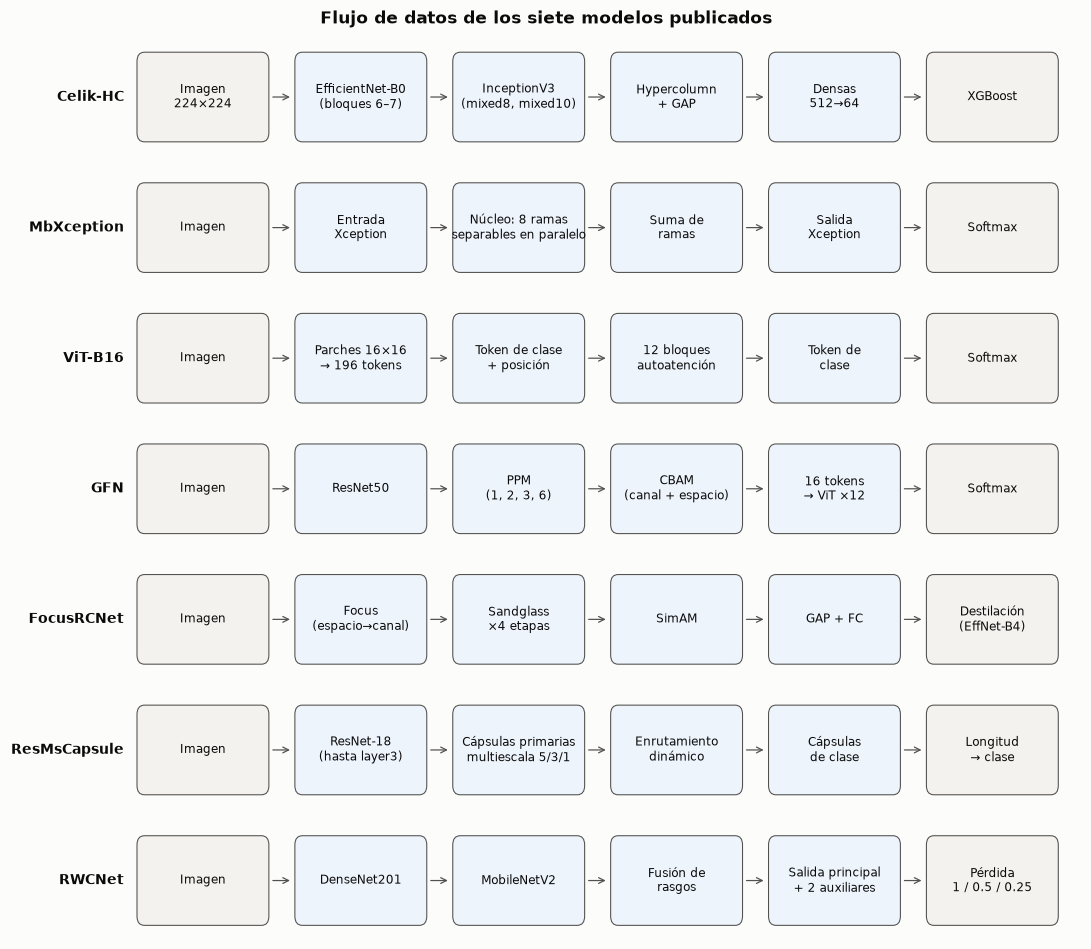

In [8]:
flujos = {
    "Celik-HC": ["Imagen\n224×224", "EfficientNet-B0\n(bloques 6–7)", "InceptionV3\n(mixed8, mixed10)", "Hypercolumn\n+ GAP", "Densas\n512→64", "XGBoost"],
    "MbXception": ["Imagen", "Entrada\nXception", "Núcleo: 8 ramas\nseparables en paralelo", "Suma de\nramas", "Salida\nXception", "Softmax"],
    "ViT-B16": ["Imagen", "Parches 16×16\n→ 196 tokens", "Token de clase\n+ posición", "12 bloques\nautoatención", "Token de\nclase", "Softmax"],
    "GFN": ["Imagen", "ResNet50", "PPM\n(1, 2, 3, 6)", "CBAM\n(canal + espacio)", "16 tokens\n→ ViT ×12", "Softmax"],
    "FocusRCNet": ["Imagen", "Focus\n(espacio→canal)", "Sandglass\n×4 etapas", "SimAM", "GAP + FC", "Destilación\n(EffNet-B4)"],
    "ResMsCapsule": ["Imagen", "ResNet-18\n(hasta layer3)", "Cápsulas primarias\nmultiescala 5/3/1", "Enrutamiento\ndinámico", "Cápsulas\nde clase", "Longitud\n→ clase"],
    "RWCNet": ["Imagen", "DenseNet201", "MobileNetV2", "Fusión de\nrasgos", "Salida principal\n+ 2 auxiliares", "Pérdida\n1 / 0.5 / 0.25"],
}
fig, axes = plt.subplots(len(flujos), 1, figsize=(10, 1.25 * len(flujos)))
for ax, (m, bl) in zip(axes, flujos.items()):
    ax.set_xlim(0, len(bl) * 1.7); ax.set_ylim(0, 1); ax.axis("off")
    for i, b in enumerate(bl):
        ax.add_patch(FancyBboxPatch((i * 1.7 + 0.05, 0.12), 1.4, 0.76, boxstyle="round,pad=0.01,rounding_size=0.08",
                                    fc="#eef4fc" if i not in (0, len(bl) - 1) else "#f3f2ee", ec=FG.INK2, lw=0.7))
        ax.text(i * 1.7 + 0.75, 0.5, b, ha="center", va="center", fontsize=7.6)
        if i < len(bl) - 1:
            ax.annotate("", (i * 1.7 + 1.72, 0.5), (i * 1.7 + 1.47, 0.5), arrowprops=dict(arrowstyle="->", color=FG.INK2, lw=0.8))
    ax.text(-0.1, 0.5, m, ha="right", va="center", fontsize=9, fontweight="bold")
fig.suptitle("Flujo de datos de los siete modelos publicados", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### 10.6.1 Celik-HC (paper guía)

- **Referencia:** Celik, G. (2025). Multi-layer feature fusion for high-accuracy solid waste classification using a hybrid deep learning model. *The Visual Computer*, *41*, 10227–10249. https://doi.org/10.1007/s00371-025-04031-3
- **Familia:** híbrido Deep Learning + *machine learning* con fusión multinivel. Se describe en detalle en el capítulo 12.
- **Bloques centrales:** $h(x) = [\mathrm{GAP}(F^{E}_{221}), \mathrm{GAP}(F^{E}_{237}), \mathrm{GAP}(F^{I}_{248}), \mathrm{GAP}(F^{I}_{310})]$ concatena rasgos de dos capas de cada red; cinco capas densas reducen $h$ a 64 dimensiones y XGBoost clasifica, $\hat y = \mathrm{XGB}(z(x))$.
- **Innovación declarada:** combinar rasgos de varias profundidades de dos redes y sustituir la *softmax* por *boosting*.
- **Resultado publicado (TrashNet):** accuracy 99.40 %, F1 99.51 %, una corrida, sin varianza ni pruebas.
- **Fortalezas:** código público completo; costo moderado (28.4 M parámetros, 3.22 GMAC).
- **Limitaciones:** la época se elige con el conjunto de prueba; la ablación del artículo varía solo las capas, no la presencia de cada red ni de XGBoost.
- **Sesgo de reporte:** los modelos de comparación se entrenan 40 épocas sin búsqueda de hiperparámetros, y la ViT reportada (397 M parámetros) no corresponde a una variante estándar.

### 10.6.2 MbXception

- **Referencia:** Shi, C., Xia, R. y Wang, L. (2020). A novel multi-branch channel expansion network for garbage image classification. *IEEE Access*, *8*, 154436–154452. https://doi.org/10.1109/ACCESS.2020.3016116
- **Familia:** CNN multirrama derivada de Xception.
- **Bloque central:** el núcleo de Xception (8 repeticiones lineales de ReLU, convolución separable y BN) se reemplaza por 8 ramas paralelas que se suman, $y = \sum_{l=1}^{8} g_l(x)$. Ensancha la red sin aumentar los parámetros frente a Xception.
- **Innovación declarada:** en TrashNet, ensanchar con ramas sumadas rinde más que profundizar o añadir atajos.
- **Resultado publicado:** accuracy 94.34 %, una corrida.
- **Fortalezas:** código oficial; análisis de oclusión en el artículo.
- **Limitaciones:** 28.4 M parámetros entrenados desde cero con unas 2500 imágenes; entrada de 229×229.
- **Sesgo de reporte:** las variantes se comparan en las mismas condiciones, pero con una sola corrida.

### 10.6.3 ViT-B16

- **Referencia:** Huang, K., Lei, H., Jiao, Z. y Zhong, Z. (2021). Recycling waste classification using vision transformer on portable device. *Sustainability*, *13*(21), 11572. https://doi.org/10.3390/su132111572
- **Familia:** Transformer con ajuste fino desde ImageNet.
- **Bloque central:** autoatención multicabeza sobre 196 parches más un token de clase, $\mathrm{Attn}(Q, K, V) = \mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$, en 12 bloques con normalización previa y red *feed-forward*.
- **Innovación declarada:** primer uso de un ViT puro en TrashNet, con despliegue en un servidor accesible desde el móvil.
- **Resultado publicado:** accuracy 96.98 %, una corrida.
- **Fortalezas:** campo receptivo global desde la primera capa.
- **Limitaciones:** 85.8 M parámetros y 17.6 GMAC; costo cuadrático en el número de parches, $O(N^2 d)$; el artículo no declara la variante, por lo que asumimos B/16.
- **Sesgo de reporte:** compara con valores de otros artículos, no con baselines entrenados en sus condiciones.

### 10.6.4 GFN

- **Referencia:** Wang, Z., Zhou, W. y Li, Y. (2025). GFN: A garbage classification fusion network incorporating multiple attention mechanisms. *Electronics*, *14*(1), 75. https://doi.org/10.3390/electronics14010075
- **Familia:** híbrido CNN-Transformer con atención.
- **Bloques centrales:**
  - **PPM:** concatena la entrada con versiones agrupadas a 1, 2, 3 y 6 celdas.
  - **CBAM:** aplica atención de canal, $M_c = \sigma(\mathrm{MLP}(\mathrm{AvgPool}(F)) + \mathrm{MLP}(\mathrm{MaxPool}(F)))$, y luego espacial, $M_s = \sigma(f^{7\times7}([\mathrm{AvgPool}(F'); \mathrm{MaxPool}(F')]))$.
  - **Codificador ViT:** recibe 16 tokens de 768 dimensiones.
- **Innovación declarada:** combinar rasgos locales de ResNet con contexto global de ViT, con atención multiescala intermedia.
- **Resultado publicado (TrashNet):** accuracy 94.21 %, una corrida.
- **Fortalezas:** ablación de componentes en el artículo, aunque sobre otro conjunto de datos.
- **Limitaciones:** 113.7 M parámetros, el mayor del benchmark; la proyección de 2048×7×7 a 1000×4×4 no se detalla.
- **Sesgo de reporte:** baselines entrenados en las mismas condiciones, con lote de 8 y una corrida.

### 10.6.5 FocusRCNet

- **Referencia:** Zheng, D., Wang, R., Duan, Y., Pang, P. C.-I. y Tan, T. (2023). Focus-RCNet: A lightweight recyclable waste classification algorithm based on focus and knowledge distillation. *Visual Computing for Industry, Biomedicine, and Art*, *6*, 19. https://doi.org/10.1186/s42492-023-00146-3
- **Familia:** CNN ligera con atención y destilación de conocimiento.
- **Bloques centrales:**
  - **Focus:** reordena cada bloque de 2×2 píxeles en 4 canales sin perder información.
  - **SimAM:** pondera cada neurona con una energía de forma cerrada, sin parámetros.
  - **Destilación:** minimiza $\mathcal L = \alpha\,T^2\,\mathrm{KL}(p^{T}_{\text{prof}} \,\|\, p^{T}_{\text{est}}) + (1-\alpha)\,\mathrm{CE}(y, p_{\text{est}})$ con un profesor EfficientNet-B4.
- **Innovación declarada:** un modelo de 0.53 M parámetros que conserva la accuracy de modelos mayores.
- **Resultado publicado:** accuracy de alrededor de 92 %, sobre el 30 % de validación.
- **Fortalezas:** el menor costo del benchmark (0.52 M parámetros y 0.13 GMAC).
- **Limitaciones:** no declara $T$ ni $\alpha$; entrada de 380×380.
- **Sesgo de reporte:** no hay conjunto de prueba separado.

### 10.6.6 ResMsCapsule

- **Referencia:** Huang, L., Li, M., Xu, T. y Dong, S.-Q. (2023). A waste classification method based on a capsule network. *Environmental Science and Pollution Research*, *30*, 86454–86462. https://doi.org/10.1007/s11356-023-27970-7
- **Familia:** red de cápsulas con extractor residual.
- **Bloque central:** las cápsulas de clase se obtienen por enrutamiento dinámico,

  $$v_j = \frac{\|s_j\|^2}{1 + \|s_j\|^2}\frac{s_j}{\|s_j\|}, \qquad s_j = \sum_i c_{ij} W_{ij} u_i,$$

  y se entrenan con la pérdida de margen,

  $$\mathcal L = \sum_k T_k \max(0, m^+ - \|v_k\|)^2 + \lambda (1 - T_k) \max(0, \|v_k\| - m^-)^2.$$

- **Innovación declarada:** cápsulas primarias multiescala sobre rasgos residuales, con el 40 % de los parámetros de ResNet-18.
- **Resultado publicado:** accuracy 91.41 %, **con cuatro clases**.
- **Fortalezas:** modela relaciones parte-todo; 4.2 M parámetros.
- **Limitaciones:** las longitudes de las cápsulas no son probabilidades calibradas (capítulo 14); los núcleos y el número de tipos de cápsula no se declaran.
- **Sesgo de reporte:** reporta el promedio de varias corridas, pero con otra tarea.

### 10.6.7 RWCNet

- **Referencia:** Hossen, M. M., Majid, M. E., Kashem, S. B. A., Khandakar, A., Nashbat, M., Ashraf, A., Hasan-Zia, M., Kunju, A. K. A., Kabir, S. y Chowdhury, M. E. H. (2024). A reliable and robust deep learning model for effective recyclable waste classification. *IEEE Access*, *12*, 13809–13821. https://doi.org/10.1109/ACCESS.2024.3354774
- **Familia:** fusión de CNN preentrenadas con salidas auxiliares.
- **Bloque central:** rasgos de DenseNet201 y MobileNetV2 se concatenan para la salida principal; dos ramas auxiliares supervisan rasgos intermedios con $\mathcal L = \mathcal L_{\text{ppal}} + 0.5\,\mathcal L_{\text{aux},1} + 0.25\,\mathcal L_{\text{aux},2}$ (supervisión profunda).
- **Innovación declarada:** combinar dos redes complementarias y supervisar etapas intermedias.
- **Resultado publicado:** accuracy 95.01 % con validación cruzada de 5 particiones e IC binomial.
- **Fortalezas:** el protocolo publicado más cuidadoso del grupo.
- **Limitaciones:** 25.6 M parámetros y la mayor memoria de entrenamiento (4.9 GB).
- **Sesgo de reporte:** baselines preentrenados con el mismo protocolo, pero con aumento de datos que podría preceder a la división.

## 10.7 Matriz comparativa y tendencias

In [9]:
mc = pd.read_csv(E2 / "results" / "summary" / "tabla_modelos.csv")
mat = mc[["model", "family", "pretrained", "params_total", "gmacs", "defines_architecture"]].copy()
mat["params (M)"] = (mat.params_total / 1e6).round(2)
pub = {"Celik-HC": "Acc 99.40 % (80/20)", "MbXception": "Acc 94.34 %", "ViT-B16": "Acc 96.98 % (70/13/17)",
       "GFN": "Acc 94.21 % (80/10/10)", "FocusRCNet": "Acc ~92 % (70/30)", "ResMsCapsule": "Acc 91.41 % (4 clases)",
       "RWCNet": "Acc 95.01 % (CV 5)"}
fort = {"Celik-HC": "código; fusión multinivel", "MbXception": "código; ancho sin más parámetros",
        "ViT-B16": "contexto global", "GFN": "local + global, atención", "FocusRCNet": "0.5 M parámetros",
        "ResMsCapsule": "parte-todo; pocos parámetros", "RWCNet": "supervisión profunda; protocolo CV"}
lim = {"Celik-HC": "época elegida con prueba", "MbXception": "desde cero, 28 M parámetros",
       "ViT-B16": "costo y datos de preentrenamiento", "GFN": "113 M parámetros", "FocusRCNet": "sin prueba separada",
       "ResMsCapsule": "4 clases; salida no calibrada", "RWCNet": "memoria de entrenamiento"}
mat["datos requeridos"] = np.where(mat.pretrained, "ImageNet-1k + TrashNet", "solo TrashNet")
mat["métrica publicada"] = mat.model.map(pub); mat["fortaleza"] = mat.model.map(fort); mat["limitación"] = mat.model.map(lim)
display(mat[["model", "family", "params (M)", "gmacs", "datos requeridos", "métrica publicada", "fortaleza", "limitación"]]
        .rename(columns={"model": "modelo", "family": "familia", "gmacs": "GMAC"}).round(2))

,modelo,familia,params (M),GMAC,datos requeridos,métrica publicada,fortaleza,limitación
0,Celik-HC,Híbrido DL + ML (fusión multinivel de CNN + XGBoost),28.42,3.22,ImageNet-1k + TrashNet,Acc 99.40 % (80/20),código; fusión multinivel,época elegida con prueba
1,MbXception,CNN multirrama (Xception modificada),28.39,6.19,solo TrashNet,Acc 94.34 %,código; ancho sin más parámetros,"desde cero, 28 M parámetros"
2,ViT-B16,Transformer (ViT con ajuste fino),85.80,17.56,ImageNet-1k + TrashNet,Acc 96.98 % (70/13/17),contexto global,costo y datos de preentrenamiento
3,GFN,Híbrido CNN-Transformer con atención (ResNet50 + PPM + CBAM + ViT),113.67,5.67,ImageNet-1k + TrashNet,Acc 94.21 % (80/10/10),"local + global, atención",113 M parámetros
4,FocusRCNet,CNN ligera con atención y destilación de conocimiento,0.52,0.13,solo TrashNet,Acc ~92 % (70/30),0.5 M parámetros,sin prueba separada
5,ResMsCapsule,Red de cápsulas con extractor residual,4.22,1.42,ImageNet-1k + TrashNet,Acc 91.41 % (4 clases),parte-todo; pocos parámetros,4 clases; salida no calibrada
6,RWCNet,Fusión de CNN preentrenadas con salidas auxiliares,25.60,4.59,ImageNet-1k + TrashNet,Acc 95.01 % (CV 5),supervisión profunda; protocolo CV,memoria de entrenamiento


**Tendencias.**

- **Preentrenamiento:** cinco de los siete modelos parten de pesos de ImageNet. Los que entrenan desde cero (MbXception y FocusRCNet) reportan las menores accuracies, salvo con destilación desde un profesor preentrenado.
- **Hibridación y atención:** los trabajos recientes (2024–2025) combinan redes o añaden atención (GFN, RWCNet, Celik-HC), con más parámetros que los modelos base.
- **Transformers:** se usan con ajuste fino; ninguno se entrena desde cero en TrashNet.
- **Eficiencia:** FocusRCNet y ResMsCapsule buscan reducir parámetros, pero sin medir latencia ni robustez.
- **Desempeño publicado:** todos reportan accuracies entre 91 % y 99 % con una sola partición aleatoria, sin varianza entre semillas ni pruebas de hipótesis.

## 10.8 Búsqueda transversal de mecanismos

Buscamos los mecanismos de los modelos del benchmark en otras modalidades para identificar candidatos transferibles al modelo propio de la etapa siguiente. Cada cadena combina:

- (i) la familia del mecanismo;
- (ii) una modalidad de origen distinta de la clasificación de residuos;
- (iii) el término *transfer* o *adaptation*.

Las cadenas se ejecutaron el 16 de noviembre de 2026 en IEEE Xplore (campo *All Metadata*, 2018–2026, con captura de pantalla de cada una en [`entregable2/revision_sistematica/capturas/`](https://github.com/Anyita-12/deep-learning-colaborativo/tree/main/entregable2/revision_sistematica/capturas)) y en arXiv y OpenAlex por API, con la respuesta cruda guardada.

La cadena T3, sobre robustez al ruido, exigía cuatro conceptos a la vez y devolvió muy pocos registros. Por eso se registró también una versión ampliada (T3b), y se reportan las dos.

In [10]:
cad = {"T1": "Fusión multinivel (Celik-HC)", "T2": "Destilación (FocusRCNet)", "T3": "Robustez al ruido (limitación del paper guía)",
       "T3b": "Robustez al ruido, versión ampliada", "T4": "Cápsulas (ResMsCapsule)", "T5": "Supervisión profunda (RWCNet)",
       "T6": "Atención de canal y espacial (GFN, FocusRCNet)"}
t = r[r.tipo == "transversal"].pivot_table(index="id", columns="base_corta", values="n_resultados", aggfunc="first")
t.insert(0, "mecanismo buscado", [cad.get(i, "") for i in t.index])
display(t)
display(r[r.tipo == "transversal"].drop_duplicates("id")[["id", "cadena_generica"]].rename(columns={"cadena_generica": "cadena"}).set_index("id"))

base_corta,mecanismo buscado,IEEE,OpenAlex,arXiv
id,,,,
T1,Fusión multinivel (Celik-HC),274,89,21
T2,Destilación (FocusRCNet),678,789,275
T3,Robustez al ruido (limitación del paper guía),180,7,3
T3b,"Robustez al ruido, versión ampliada",95,28,15
T4,Cápsulas (ResMsCapsule),161,83,10
T5,Supervisión profunda (RWCNet),219,137,63
T6,"Atención de canal y espacial (GFN, FocusRCNet)",1100,447,91


,cadena
id,
T1,"(""hypercolumn"" OR ""multi-level feature fusion"" OR ""multi-layer feature fusio..."
T2,"(""knowledge distillation"") AND (""speech"" OR ""natural language"" OR ""time seri..."
T3,"(""noise robustness"" OR ""robustness to noise"" OR ""corruption robustness"" OR ""..."
T3b,"(""noise robustness"" OR ""robustness to noise"" OR ""corruption robustness"" OR ""..."
T4,"(""capsule network"" OR ""capsule networks"") AND (""text"" OR ""signal"" OR ""EEG"" O..."
T5,"(""deep supervision"" OR ""auxiliary loss"" OR ""auxiliary classifier"") AND (""seg..."
T6,"(""channel attention"" OR ""spatial attention"" OR ""CBAM"") AND (""time series"" OR..."


**Tabla de mecanismos candidatos.** Para cada mecanismo registramos:

- la aplicación de origen;
- la fuente primaria, verificada contra OpenAlex o arXiv;
- ejemplos de transferencia a otras modalidades, tomados de los registros de las cadenas T1–T6;
- la propiedad estructural que comparte con TrashNet;
- una valoración preliminar de transferibilidad frente a la evidencia del propio benchmark.

In [11]:
tm = pd.read_csv(RS / "tabla_mecanismos.csv", encoding="utf-8-sig")
display(tm[["id", "mecanismo", "modelo_top10", "aplicacion_modalidad_origen", "fuente_primaria", "propiedad_estructural_compartida",
            "transferibilidad_preliminar"]].set_index("id"))

,mecanismo,modelo_top10,aplicacion_modalidad_origen,fuente_primaria,propiedad_estructural_compartida,transferibilidad_preliminar
id,,,,,,
M1,Destilación de conocimiento (maestro grande → alumno ligero),FocusRCNet,Compresión de modelos; lenguaje y voz,"Hinton et al. 2015, arXiv:1503.02531",Dataset pequeño y necesidad de modelo ligero; hay un maestro robusto disponi...,Alta
M2,Entrenamiento y aumentación con ruido / corrupciones,Ninguno del Top 10 (es la limitación),Voz y audio; imagen médica,"Hendrycks y Dietterich 2019, arXiv:1903.12261",Mismo tipo de perturbación (ruido gaussiano de sensor o cámara) que hace col...,Alta
M3,Supervisión profunda / salidas auxiliares,RWCNet,Segmentación médica y teledetección,"Lee et al. 2015, arXiv:1409.5185; Szegedy et al. 2015, 10.1109/cvpr.2015.729...",Pocos datos: regulariza las capas intermedias,Alta
M4,Self-attention / Transformer,"ViT-B16, GFN",Lenguaje (traducción),"Vaswani et al. 2017, arXiv:1706.03762; Dosovitskiy et al. 2021, arXiv:2010.1...",Contexto global; menor sesgo hacia texturas de alta frecuencia,Alta
M5,Adaptación de dominio adversarial,Ninguno del Top 10,"Teledetección, EEG, diagnóstico de fallas","Ganin y Lempitsky 2015, arXiv:1409.7495",Cambio de dominio: TrashNet tiene fondo blanco y el uso real no (caída con f...,Media
M6,"Atención de canal y espacial (SE, CBAM) y pooling piramidal","GFN, FocusRCNet (SimAM)","Visión (ImageNet, segmentación); luego series y señales","Hu et al. 2018, 10.1109/cvpr.2018.00745; Woo et al. 2018, 10.1007/978-3-030-...",Separar el objeto del fondo (Grad-CAM muestra energía en el fondo),Media
M7,Redes de cápsulas,ResMsCapsule,"Dígitos (MNIST); luego texto, EEG y fallas","Sabour et al. 2017, arXiv:1710.09829",Relaciones parte-todo y pose de objetos deformados,Media
M8,Fusión multinivel (hypercolumn),Celik-HC (paper guía),Segmentación y localización fina,"Hariharan et al. 2015, 10.1109/cvpr.2015.7298642",Texturas finas para distinguir materiales,Baja
M9,Gradient boosting sobre embeddings profundos,Celik-HC (paper guía),Datos tabulares,"Chen y Guestrin 2016, 10.1145/2939672.2939785",Clasificador final sobre vector de 64 dimensiones,Baja


Los mecanismos con mayor transferibilidad atacan la limitación cuantificada del paper guía, su fragilidad ante el ruido (capítulos 12 y 15):

- **M1, destilación:** destilar la robustez de un maestro Transformer hacia un alumno ligero.
- **M2, entrenamiento con ruido y corrupciones:** la intervención más directa contra esa limitación.
- **M4, atención global:** ViT-B16 es el único modelo del benchmark que casi no se degrada con ruido.

La cadena T3b muestra que la combinación de destilación y robustez al ruido ya se usa en reconocimiento de voz. En cambio, la evidencia propia del benchmark resta transferibilidad a otros mecanismos:

- **M8, fusión multinivel:** no aporta en la ablación del paper guía.
- **M9, *boosting* sobre *embeddings*:** empeora frente a la *softmax*.
- **M7, cápsulas:** son mal calibradas y frágiles al ruido.

La tabla no compromete la elección final del modelo propio.

Las exportaciones de siete cadenas preliminares de mecanismos (M1–M7), ejecutadas en Scopus e IEEE Xplore antes de fijar las cadenas T1–T6 y sin el conteo total, se conservan en [`entregable2/results/revision/cadenas_preliminares_M1_M7/`](https://github.com/Anyita-12/deep-learning-colaborativo/tree/main/entregable2/results/revision/cadenas_preliminares_M1_M7) como registro.

## 10.9 Brecha de investigación

> Ninguno de los 59 estudios incluidos compara modelos publicados de al menos cuatro familias sobre TrashNet con una partición que controle los casi-duplicados, varias semillas e inferencia estadística, ni compara con inferencia estadística la robustez de esos modelos ante ruido de imagen.

La brecha tiene dos partes, y cada una se puede refutar con la hoja de extracción ([`hoja_extraccion.csv`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/revision_sistematica/datos/hoja_extraccion.csv)) y con el cribado del benchmark ([`cribado_e2.csv`](https://github.com/Anyita-12/deep-learning-colaborativo/blob/main/entregable2/results/revision/cribado_e2.csv)).

**Comparación controlada.**

- **Familias:** solo 2 de los 59 estudios abarcan cuatro familias de arquitectura (Yusiong, 2022; Yang et al., 2026), y ninguno de los dos aplica pruebas estadísticas.
- **Réplicas e inferencia:** 9 estudios reportan más de una corrida y 9 usan alguna prueba estadística. Solo 4 combinan ambas, con dos o tres familias cada uno.
- **Fuga:** ninguno de los 59 tiene riesgo de fuga bajo.
- **Estudios del benchmark:** ninguno de los siete compara modelos con pruebas de hipótesis.

**Robustez ante ruido.** 6 de los 59 textos mencionan ruido o corrupción de imagen (indicador `ruido_corrupcion`). Solo uno mide el efecto del ruido gaussiano sobre imágenes de prueba de TrashNet: Liu et al. (2026) reportan que la accuracy de su modelo ResSeMo cae 4.1 puntos con $\sigma = 0.05$, frente a modelos como VGG16, en una corrida y sin prueba estadística. Los demás usan el ruido como aumento de datos, lo mencionan como motivación o evalúan fondos complejos (Qin et al., 2022), no ruido.

La brecha conecta con las preguntas de investigación del capítulo 8:

- **RQ1 y RQ2:** la primera parte, con el benchmark controlado.
- **RQ3 y RQ4:** la primera parte aplicada al paper guía, con su réplica y su ablación.
- **RQ5:** la segunda parte, con la robustez ante ruido de los diez modelos.

## 10.10 Alcance de la revisión

1. **Foco en TrashNet:** la cadena definitiva restringe la revisión a los estudios evaluados en TrashNet, para garantizar la comparabilidad con nuestro conjunto de datos. Los estudios de clasificación de residuos con otros conjuntos de datos quedan identificados en la búsqueda ampliada (sección 10.3).
2. **Priorización de la lectura a texto completo:** el análisis detallado se concentró en los 62 registros de prioridad Alta; los demás quedan clasificados en el Excel de selección.
3. **Selección asistida por IA y verificada por personas:** el cribado preliminar y la lectura a texto completo se apoyaron en IA. Dos revisores humanos validaron el cribado en una muestra común ($\kappa = 0.857$) y los siete estudios del benchmark se verificaron a mano.
4. **Extracción con patrones explícitos:** los indicadores de la hoja de extracción y del cribado del benchmark se obtienen con reglas reproducibles sobre el texto completo y se verificaron a mano en los siete estudios del benchmark.
5. **Bases de la búsqueda ampliada:** IEEE Xplore aporta los conteos en una base principal, y arXiv y OpenAlex los registros completos para el cribado reproducible.